# Implementasi Python pada Distribusi Probabilitas

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mirna-HZ/ProbabilitasStatistika_Python_Mirna/blob/main/Tugas_Eksplorasi_Python/02_Distribusi_Probabilitas.ipynb)

## Import Library

In [1]:
import math
import statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sympy as sp
from scipy import stats, integrate

rng = np.random.default_rng(2026)   # seed agar hasil simulasi bisa diulang

## D1. Distribusi Bernoulli: Keberhasilan Build CI/CD

**Soal:** Sebuah pipeline CI/CD berhasil menyelesaikan build dengan peluang 0,78. Misalkan X = 1 jika build berhasil dan X = 0 jika gagal. Tentukan P(X = 1), P(X = 0), E[X], dan Var[X], lalu bandingkan dengan simulasi 10.000 build.

**Perhitungan manual:**

- P(X = 1) = p = 0,78 dan P(X = 0) = 1 - p = 0,22.
- E[X] = p = 0,78.
- Var[X] = p(1 - p) = 0,78 x 0,22 = 0,1716.

P(X = 1) = 0.78 | P(X = 0) = 0.22
E[X]   scipy = 0.78 | manual p = 0.78
Var[X] scipy = 0.1716 | manual p(1-p) = 0.1716

Simulasi 10.000 build:
Proporsi berhasil (statistics.mean)   = 0.7748
Varians sampel (statistics.pvariance) = 0.1745


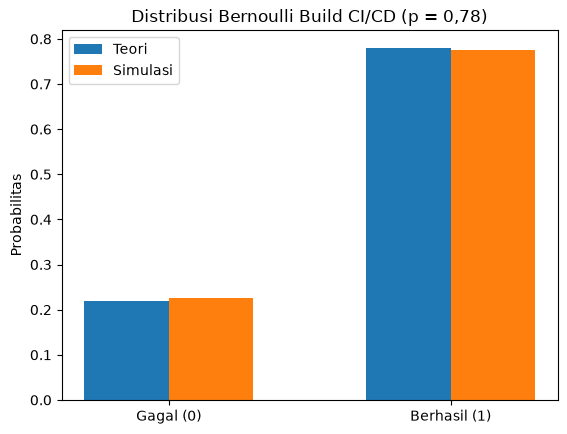

In [2]:
p = 0.78
X = stats.bernoulli(p)
print("P(X = 1) =", X.pmf(1), "| P(X = 0) =", round(X.pmf(0), 2))
print("E[X]   scipy =", X.mean(), "| manual p =", p)
print("Var[X] scipy =", round(X.var(), 4), "| manual p(1-p) =", round(p * (1 - p), 4))

sampel = X.rvs(size=10_000, random_state=rng)
print("\nSimulasi 10.000 build:")
print("Proporsi berhasil (statistics.mean)   =", statistics.mean(sampel.tolist()))
print("Varians sampel (statistics.pvariance) =", round(statistics.pvariance(sampel.tolist()), 4))

nilai = [0, 1]
plt.bar([-0.15, 0.85], X.pmf(nilai), width=0.3, label="Teori")
plt.bar([0.15, 1.15], [np.mean(sampel == 0), np.mean(sampel == 1)], width=0.3, label="Simulasi")
plt.xticks(nilai, ["Gagal (0)", "Berhasil (1)"])
plt.ylabel("Probabilitas")
plt.title("Distribusi Bernoulli Build CI/CD (p = 0,78)")
plt.legend()
plt.show()

## D2. Distribusi Binomial: Email Notifikasi Masuk Folder Spam

**Soal:** Sebuah sistem mengirim 12 email notifikasi. Setiap email masuk ke folder spam secara saling bebas dengan peluang 0,1. Misalkan X adalah banyak email yang masuk folder spam. Tentukan P(X = 0), P(X = 2), P(X <= 2), P(X >= 3), E[X], dan Var[X], serta gambarkan PMF dan CDF-nya.

**Perhitungan manual:**

- X ~ Binomial(n = 12, p = 0,1) dengan P(X = k) = C(12,k) (0,1)^k (0,9)^(12-k).
- P(X = 0) = 0,9^12 = 0,2824 dan P(X = 2) = 66 x 0,01 x 0,9^10 = 0,2301.
- P(X = 1) = 12 x 0,1 x 0,9^11 = 0,3766, sehingga P(X <= 2) = 0,2824 + 0,3766 + 0,2301 = 0,8891 dan P(X >= 3) = 0,1109.
- E[X] = np = 1,2 dan Var[X] = np(1 - p) = 1,08.

P(X = 0)  manual = 0.2824 | scipy = 0.2824
P(X = 2)  manual = 0.2301 | scipy = 0.2301
P(X <= 2) manual = 0.8891 | scipy = 0.8891
P(X >= 3) scipy  = 0.1109
E[X] = 1.20 (np = 1.20) | Var[X] = 1.0800 (np(1-p) = 1.0800)

 k  P(X=k)  P(X<=k)
 0  0.2824   0.2824
 1  0.3766   0.6590
 2  0.2301   0.8891
 3  0.0852   0.9744
 4  0.0213   0.9957
 5  0.0038   0.9995
 6  0.0005   0.9999
 7  0.0000   1.0000


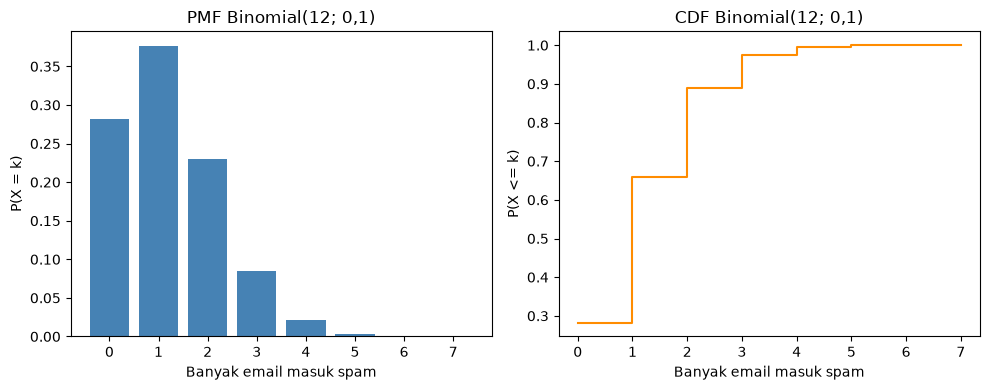

In [3]:
n, p = 12, 0.1
X = stats.binom(n, p)

def pmf_manual(k):
    return math.comb(n, k) * p**k * (1 - p)**(n - k)

print(f"P(X = 0)  manual = {pmf_manual(0):.4f} | scipy = {X.pmf(0):.4f}")
print(f"P(X = 2)  manual = {pmf_manual(2):.4f} | scipy = {X.pmf(2):.4f}")
print(f"P(X <= 2) manual = {sum(pmf_manual(k) for k in range(3)):.4f} | scipy = {X.cdf(2):.4f}")
print(f"P(X >= 3) scipy  = {X.sf(2):.4f}")
print(f"E[X] = {X.mean():.2f} (np = {n * p:.2f}) | Var[X] = {X.var():.4f} (np(1-p) = {n * p * (1 - p):.4f})")

k = np.arange(0, 8)
tabel = pd.DataFrame({"k": k, "P(X=k)": X.pmf(k), "P(X<=k)": X.cdf(k)})
print("\n" + tabel.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(k, X.pmf(k), color="steelblue")
ax[0].set_title("PMF Binomial(12; 0,1)")
ax[0].set_xlabel("Banyak email masuk spam")
ax[0].set_ylabel("P(X = k)")
ax[1].step(k, X.cdf(k), where="post", color="darkorange")
ax[1].set_title("CDF Binomial(12; 0,1)")
ax[1].set_xlabel("Banyak email masuk spam")
ax[1].set_ylabel("P(X <= k)")
plt.tight_layout()
plt.show()

## D3. Distribusi Poisson: Tiket Helpdesk IT per Jam

**Soal:** Helpdesk IT kampus menerima rata-rata 6 tiket keluhan per jam dan banyak tiket per jam mengikuti distribusi Poisson. Tentukan P(X = 0), P(X = 6), P(X > 9), E[X], Var[X], serta kapasitas penanganan minimum agar 99% jam tidak kewalahan. Simulasikan juga banyak tiket selama 30 hari kerja (240 jam).

**Perhitungan manual:**

- P(X = k) = e^(-6) 6^k / k!.
- P(X = 0) = e^(-6) = 0,0025 dan P(X = 6) = e^(-6) x 46656/720 = 0,1606.
- P(X > 9) = 1 - P(X <= 9) = 1 - 0,9161 = 0,0839.
- E[X] = Var[X] = 6. Kapasitas dicari dari k terkecil dengan P(X <= k) >= 0,99.

P(X = 0) manual = 0.0025 | scipy = 0.0025
P(X = 6) manual = 0.1606 | scipy = 0.1606
P(X > 9)        = 0.0839
E[X] = 6.0 | Var[X] = 6.0
Kapasitas minimum 99% : 12 tiket/jam (P(X <= 12) = 0.9912)

Simulasi 240 jam: rata-rata = 5.912, varians = 5.672
Jam dengan tiket > 12: 1 jam


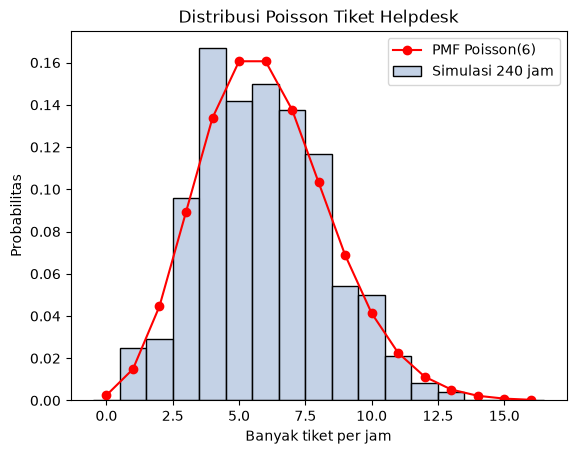

In [4]:
lam = 6
X = stats.poisson(lam)
print(f"P(X = 0) manual = {math.exp(-lam):.4f} | scipy = {X.pmf(0):.4f}")
print(f"P(X = 6) manual = {math.exp(-lam) * lam**6 / math.factorial(6):.4f} | scipy = {X.pmf(6):.4f}")
print(f"P(X > 9)        = {X.sf(9):.4f}")
print(f"E[X] = {X.mean()} | Var[X] = {X.var()}")
kap = int(X.ppf(0.99))
print(f"Kapasitas minimum 99% : {kap} tiket/jam (P(X <= {kap}) = {X.cdf(kap):.4f})")

# Simulasi banyak tiket tiap jam selama 240 jam kerja
sim = rng.poisson(lam, 240)
print(f"\nSimulasi 240 jam: rata-rata = {sim.mean():.3f}, varians = {sim.var():.3f}")
print(f"Jam dengan tiket > {kap}: {np.sum(sim > kap)} jam")

k = np.arange(0, 17)
sns.histplot(sim, bins=np.arange(-0.5, 17.5, 1), stat="probability",
             color="lightsteelblue", label="Simulasi 240 jam")
plt.plot(k, X.pmf(k), "ro-", label="PMF Poisson(6)")
plt.xlabel("Banyak tiket per jam")
plt.ylabel("Probabilitas")
plt.title("Distribusi Poisson Tiket Helpdesk")
plt.legend()
plt.show()

## D4. Aproksimasi Poisson terhadap Binomial: Bug pada Kode Program

**Soal:** Sebuah program terdiri dari 2000 baris kode. Setiap baris memiliki peluang 0,001 mengandung bug secara saling bebas. Bandingkan peluang banyak bug yang dihitung dengan distribusi Binomial(2000; 0,001) dan aproksimasi Poisson dengan lambda = np = 2.

**Perhitungan manual:**

- n besar dan p kecil sehingga Binomial dapat didekati Poisson dengan lambda = 2000 x 0,001 = 2.
- Contoh: P(X = 0) Binomial = 0,999^2000 = 0,1352, Poisson = e^(-2) = 0,1353.
- P(minimal 1 bug) = 1 - P(X = 0), kira-kira 0,8647 pada kedua distribusi.

 k  Binomial  Poisson  Selisih
 0   0.13520  0.13534  0.00014
 1   0.27067  0.27067  0.00000
 2   0.27081  0.27067  0.00014
 3   0.18054  0.18045  0.00009
 4   0.09022  0.09022  0.00000
 5   0.03605  0.03609  0.00004
 6   0.01200  0.01203  0.00003
 7   0.00342  0.00344  0.00002
 8   0.00085  0.00086  0.00001

Selisih maksimum: 0.000135
P(minimal 1 bug): Binomial = 0.86480 | Poisson = 0.86466


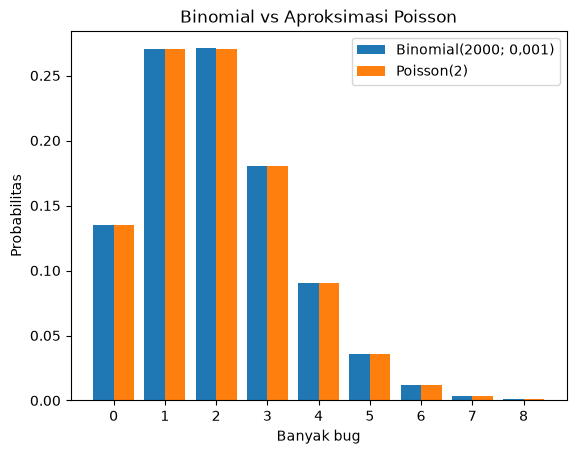

In [5]:
n, p = 2000, 0.001
lam = n * p
k = np.arange(0, 9)
banding = pd.DataFrame({
    "k": k,
    "Binomial": stats.binom.pmf(k, n, p),
    "Poisson": stats.poisson.pmf(k, lam)
})
banding["Selisih"] = (banding["Binomial"] - banding["Poisson"]).abs()
print(banding.round(5).to_string(index=False))
print("\nSelisih maksimum:", round(banding["Selisih"].max(), 6))
print(f"P(minimal 1 bug): Binomial = {stats.binom.sf(0, n, p):.5f} | Poisson = {stats.poisson.sf(0, lam):.5f}")

lebar = 0.4
plt.bar(k - lebar / 2, banding["Binomial"], width=lebar, label="Binomial(2000; 0,001)")
plt.bar(k + lebar / 2, banding["Poisson"], width=lebar, label="Poisson(2)")
plt.xticks(k)
plt.xlabel("Banyak bug")
plt.ylabel("Probabilitas")
plt.title("Binomial vs Aproksimasi Poisson")
plt.legend()
plt.show()

## D5. Distribusi Geometrik: Pengujian Acak hingga Bug Pertama Ditemukan

**Soal:** Seorang tester menjalankan test case yang dibangkitkan secara acak. Setiap test case menemukan bug dengan peluang 0,15 secara saling bebas. Misalkan X adalah urutan test case saat bug pertama ditemukan. Tentukan P(X = 4), P(X <= 5), P(X > 10), E[X], dan Var[X].

**Perhitungan manual:**

- P(X = k) = (1 - p)^(k-1) p, sehingga P(X = 4) = 0,85^3 x 0,15 = 0,0921.
- P(X <= 5) = 1 - 0,85^5 = 1 - 0,4437 = 0,5563 dan P(X > 10) = 0,85^10 = 0,1969.
- E[X] = 1/p = 6,6667 dan Var[X] = (1 - p)/p^2 = 0,85/0,0225 = 37,7778.

P(X = 4)   manual = 0.0921 | scipy = 0.0921
P(X <= 5)  manual = 0.5563 | scipy = 0.5563
P(X > 10)  scipy  = 0.1969
E[X]   = 6.6667 (1/p = 6.6667)
Var[X] = 37.7778 ((1-p)/p^2 = 37.7778)
Banyak test agar bug ditemukan dengan peluang 90%: 15

Simulasi: rata-rata = 6.6217, varians = 37.7491


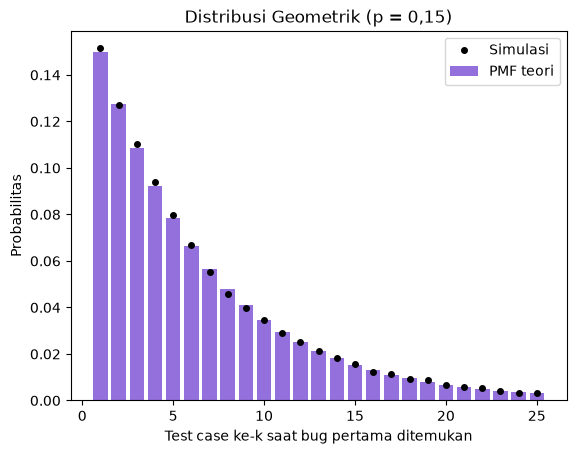

In [6]:
p = 0.15
X = stats.geom(p)   # support mulai dari 1 (test case ke-1, ke-2, ...)
print(f"P(X = 4)   manual = {(1 - p)**3 * p:.4f} | scipy = {X.pmf(4):.4f}")
print(f"P(X <= 5)  manual = {1 - (1 - p)**5:.4f} | scipy = {X.cdf(5):.4f}")
print(f"P(X > 10)  scipy  = {X.sf(10):.4f}")
print(f"E[X]   = {X.mean():.4f} (1/p = {1 / p:.4f})")
print(f"Var[X] = {X.var():.4f} ((1-p)/p^2 = {(1 - p) / p**2:.4f})")
print(f"Banyak test agar bug ditemukan dengan peluang 90%: {int(X.ppf(0.90))}")

# Simulasi 50.000 sesi pengujian
sim = rng.geometric(p, 50_000)
print(f"\nSimulasi: rata-rata = {sim.mean():.4f}, varians = {sim.var():.4f}")

k = np.arange(1, 26)
plt.bar(k, X.pmf(k), color="mediumpurple", label="PMF teori")
plt.plot(k, [np.mean(sim == i) for i in k], "ko", markersize=4, label="Simulasi")
plt.xlabel("Test case ke-k saat bug pertama ditemukan")
plt.ylabel("Probabilitas")
plt.title("Distribusi Geometrik (p = 0,15)")
plt.legend()
plt.show()

## D6. Distribusi Hipergeometrik: Quality Control SSD dari Pemasok

**Soal:** Sebuah kampus menerima 30 unit SSD dari pemasok, 4 di antaranya cacat. Bagian IT memeriksa 6 unit yang dipilih acak tanpa pengembalian. Misalkan X adalah banyak SSD cacat yang ditemukan. Tentukan P(X = 0), P(X = 1), P(X >= 1), E[X], dan Var[X], lalu bandingkan dengan pendekatan Binomial.

**Perhitungan manual:**

- P(X = k) = C(4,k) C(26,6-k) / C(30,6).
- P(X = 0) = C(26,6)/C(30,6) = 230230/593775 = 0,3877, sehingga P(X >= 1) = 0,6123.
- E[X] = n K/N = 6 x 4/30 = 0,8.
- Var[X] = n (K/N)(1 - K/N)(N - n)/(N - 1) = 6 x (4/30) x (26/30) x 24/29 = 0,5738.

P(X = 0)  manual = 0.3877 | scipy = 0.3877
P(X = 1)  scipy  = 0.4431
P(X >= 1) scipy  = 0.6123
E[X] = 0.8000 | Var[X] = 0.5738


Simulasi P(X >= 1) = 0.6149

 k  Hipergeometrik  Binomial(6; 0,1333)  Simulasi
 0          0.3877               0.4238    0.3851
 1          0.4431               0.3912    0.4472
 2          0.1511               0.1504    0.1506
 3          0.0175               0.0309    0.0164
 4          0.0005               0.0036    0.0006


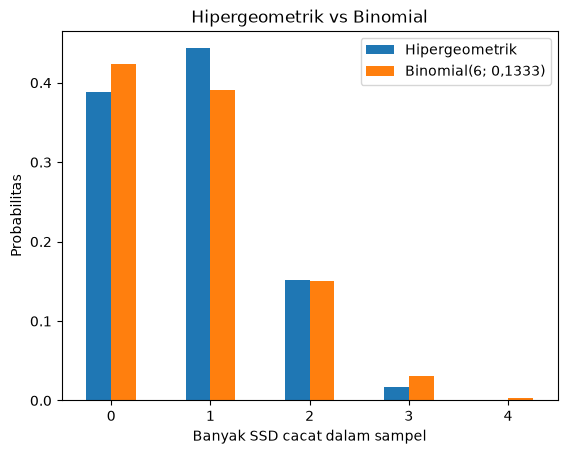

In [7]:
N, K, n = 30, 4, 6
X = stats.hypergeom(M=N, n=K, N=n)   # M = populasi, n = jumlah "sukses", N = sampel

p0_manual = math.comb(K, 0) * math.comb(N - K, n) / math.comb(N, n)
print(f"P(X = 0)  manual = {p0_manual:.4f} | scipy = {X.pmf(0):.4f}")
print(f"P(X = 1)  scipy  = {X.pmf(1):.4f}")
print(f"P(X >= 1) scipy  = {X.sf(0):.4f}")
print(f"E[X] = {X.mean():.4f} | Var[X] = {X.var():.4f}")

# Simulasi 20.000 kali pemeriksaan tanpa pengembalian
populasi = np.array([1] * K + [0] * (N - K))
sim = np.array([rng.choice(populasi, n, replace=False).sum() for _ in range(20_000)])
print(f"Simulasi P(X >= 1) = {np.mean(sim >= 1):.4f}")

k = np.arange(0, K + 1)
banding = pd.DataFrame({"k": k,
                        "Hipergeometrik": X.pmf(k),
                        "Binomial(6; 0,1333)": stats.binom.pmf(k, n, K / N),
                        "Simulasi": [np.mean(sim == i) for i in k]})
print("\n" + banding.round(4).to_string(index=False))

banding.set_index("k")[["Hipergeometrik", "Binomial(6; 0,1333)"]].plot(kind="bar")
plt.xticks(rotation=0)
plt.xlabel("Banyak SSD cacat dalam sampel")
plt.ylabel("Probabilitas")
plt.title("Hipergeometrik vs Binomial")
plt.show()

## D7. Distribusi Uniform Kontinu: Waktu Respons Server

**Soal:** Waktu respons sebuah server tersebar merata antara 20 ms dan 80 ms. Tentukan P(30 < X < 45), P(X > 70), E[X], Var[X], dan bandingkan dengan simulasi 100.000 request.

**Perhitungan manual:**

- f(x) = 1/(80 - 20) = 1/60 untuk 20 <= x <= 80.
- P(30 < X < 45) = (45 - 30)/60 = 0,25 dan P(X > 70) = (80 - 70)/60 = 0,1667.
- E[X] = (20 + 80)/2 = 50 ms dan Var[X] = (80 - 20)^2/12 = 300 ms^2.

P(30 < X < 45) = 0.2500 (manual 15/60 = 0.2500)
P(X > 70)      = 0.1667 (manual 10/60 = 0.1667)
E[X] = 50.0 ms | Var[X] = 300.0 ms^2 | SD = 17.321 ms

Simulasi: P(30 < X < 45) = 0.2506, rata-rata = 49.934, varians = 300.093


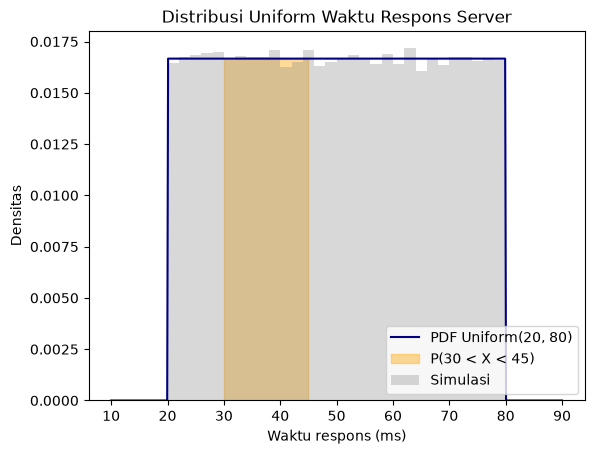

In [8]:
a, b = 20, 80
X = stats.uniform(loc=a, scale=b - a)
print(f"P(30 < X < 45) = {X.cdf(45) - X.cdf(30):.4f} (manual 15/60 = {15 / 60:.4f})")
print(f"P(X > 70)      = {X.sf(70):.4f} (manual 10/60 = {10 / 60:.4f})")
print(f"E[X] = {X.mean()} ms | Var[X] = {X.var():.1f} ms^2 | SD = {X.std():.3f} ms")

sim = X.rvs(size=100_000, random_state=rng)
print(f"\nSimulasi: P(30 < X < 45) = {np.mean((sim > 30) & (sim < 45)):.4f}, "
      f"rata-rata = {sim.mean():.3f}, varians = {sim.var():.3f}")

x = np.linspace(10, 90, 500)
plt.plot(x, X.pdf(x), color="navy", label="PDF Uniform(20, 80)")
xs = np.linspace(30, 45, 100)
plt.fill_between(xs, X.pdf(xs), alpha=0.4, color="orange", label="P(30 < X < 45)")
plt.hist(sim, bins=30, density=True, alpha=0.3, color="gray", label="Simulasi")
plt.xlabel("Waktu respons (ms)")
plt.ylabel("Densitas")
plt.title("Distribusi Uniform Waktu Respons Server")
plt.legend()
plt.show()

## D8. Distribusi Normal: Suhu CPU saat Beban Penuh

**Soal:** Suhu CPU sebuah server saat beban penuh berdistribusi normal dengan rata-rata 72 derajat Celsius dan simpangan baku 6 derajat. Tentukan P(X > 80), P(65 < X < 80), suhu yang hanya dilampaui 5% waktu (persentil ke-95), dan periksa aturan empiris 68-95-99,7 melalui simulasi.

**Perhitungan manual:**

- Z = (X - 72)/6. Untuk X = 80 diperoleh Z = 1,33 dan untuk X = 65 diperoleh Z = -1,17.
- P(X > 80) = P(Z > 1,33) = 0,0912.
- P(65 < X < 80) = P(-1,17 < Z < 1,33) = 0,9088 - 0,1217 = 0,7871.
- Persentil ke-95: x = 72 + 1,645 x 6 = 81,87 derajat Celsius.

Z untuk 80 = 1.3333 | Z untuk 65 = -1.1667
P(X > 80)       = 0.0912 | via Z: 0.0912
P(65 < X < 80)  = 0.7871
Persentil ke-95 = 81.87 derajat Celsius
Proporsi dalam 1 SD: simulasi = 0.6832 | teori = 0.6827
Proporsi dalam 2 SD: simulasi = 0.9540 | teori = 0.9545
Proporsi dalam 3 SD: simulasi = 0.9973 | teori = 0.9973


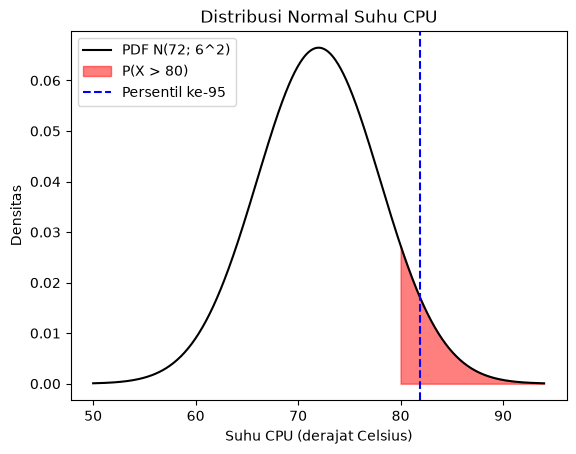

In [9]:
mu, sigma = 72, 6
X = stats.norm(mu, sigma)

z80, z65 = (80 - mu) / sigma, (65 - mu) / sigma
print(f"Z untuk 80 = {z80:.4f} | Z untuk 65 = {z65:.4f}")
print(f"P(X > 80)       = {X.sf(80):.4f} | via Z: {1 - stats.norm.cdf(z80):.4f}")
print(f"P(65 < X < 80)  = {X.cdf(80) - X.cdf(65):.4f}")
print(f"Persentil ke-95 = {X.ppf(0.95):.2f} derajat Celsius")

# Aturan empiris dengan simulasi 100.000 pengukuran
sim = rng.normal(mu, sigma, 100_000)
for k in [1, 2, 3]:
    prop = np.mean(np.abs(sim - mu) < k * sigma)
    print(f"Proporsi dalam {k} SD: simulasi = {prop:.4f} | teori = {X.cdf(mu + k * sigma) - X.cdf(mu - k * sigma):.4f}")

x = np.linspace(50, 94, 500)
plt.plot(x, X.pdf(x), color="black", label="PDF N(72; 6^2)")
xs = np.linspace(80, 94, 100)
plt.fill_between(xs, X.pdf(xs), color="red", alpha=0.5, label="P(X > 80)")
plt.axvline(X.ppf(0.95), color="blue", linestyle="--", label="Persentil ke-95")
plt.xlabel("Suhu CPU (derajat Celsius)")
plt.ylabel("Densitas")
plt.title("Distribusi Normal Suhu CPU")
plt.legend()
plt.show()

## D9. Aproksimasi Normal terhadap Binomial: Ulasan Aplikasi

**Soal:** Sebuah aplikasi diunduh oleh 400 pengguna. Setiap pengguna memberikan ulasan dengan peluang 0,3 secara saling bebas. Tentukan peluang minimal 130 pengguna memberikan ulasan dengan distribusi Binomial secara eksak dan dengan aproksimasi Normal (dengan koreksi kontinuitas).

**Perhitungan manual:**

- mu = np = 400 x 0,3 = 120 dan sigma = akar(np(1 - p)) = akar(84) = 9,165.
- Dengan koreksi kontinuitas: P(X >= 130) kira-kira P(Z >= (129,5 - 120)/9,165) = P(Z >= 1,037) = 0,1500.

mu = 120.0, sigma = 9.1652
P(X >= 130) Binomial eksak           = 0.1501
P(X >= 130) Normal + koreksi 0,5     = 0.1500
P(X >= 130) Normal tanpa koreksi     = 0.1376


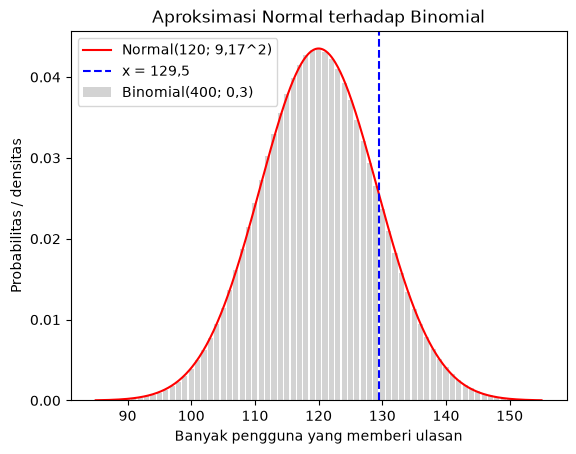

In [10]:
n, p = 400, 0.3
mu = n * p
sigma = math.sqrt(n * p * (1 - p))
print(f"mu = {mu}, sigma = {sigma:.4f}")

p_eksak = stats.binom.sf(129, n, p)                 # P(X >= 130)
p_normal = stats.norm.sf(129.5, mu, sigma)          # dengan koreksi kontinuitas
p_normal_tanpa = stats.norm.sf(130, mu, sigma)      # tanpa koreksi
print(f"P(X >= 130) Binomial eksak           = {p_eksak:.4f}")
print(f"P(X >= 130) Normal + koreksi 0,5     = {p_normal:.4f}")
print(f"P(X >= 130) Normal tanpa koreksi     = {p_normal_tanpa:.4f}")

k = np.arange(85, 156)
x = np.linspace(85, 155, 500)
plt.bar(k, stats.binom.pmf(k, n, p), color="lightgray", label="Binomial(400; 0,3)")
plt.plot(x, stats.norm.pdf(x, mu, sigma), color="red", label="Normal(120; 9,17^2)")
plt.axvline(129.5, color="blue", linestyle="--", label="x = 129,5")
plt.xlabel("Banyak pengguna yang memberi ulasan")
plt.ylabel("Probabilitas / densitas")
plt.title("Aproksimasi Normal terhadap Binomial")
plt.legend()
plt.show()

## D10. Distribusi Eksponensial: Lama Sesi Pengguna Aplikasi

**Soal:** Lama sesi pengguna pada sebuah aplikasi berdistribusi eksponensial dengan rata-rata 8 menit. Tentukan P(T < 5), P(T > 20), median lama sesi, dan buktikan sifat tanpa ingatan (memoryless) P(T > 15 | T > 5) = P(T > 10) melalui simulasi.

**Perhitungan manual:**

- lambda = 1/8 per menit, F(t) = 1 - e^(-t/8).
- P(T < 5) = 1 - e^(-0,625) = 0,4647 dan P(T > 20) = e^(-2,5) = 0,0821.
- Median = 8 ln 2 = 5,545 menit.
- Sifat tanpa ingatan: P(T > 15 | T > 5) = e^(-15/8)/e^(-5/8) = e^(-1,25) = 0,2865 = P(T > 10).

P(T < 5)  = 0.4647 | manual = 0.4647
P(T > 20) = 0.0821 | manual = 0.0821
Median    = 5.545 menit | manual = 5.545
E[T] = 8.0 menit | Var[T] = 64.0 menit^2

Simulasi P(T > 15 | T > 5) = 0.2857
Teori    P(T > 10)         = 0.2865


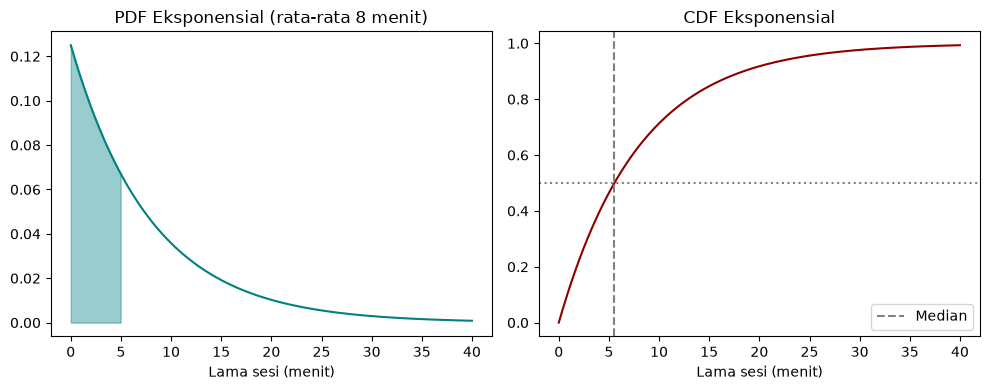

In [11]:
rata = 8
T = stats.expon(scale=rata)
print(f"P(T < 5)  = {T.cdf(5):.4f} | manual = {1 - math.exp(-5 / rata):.4f}")
print(f"P(T > 20) = {T.sf(20):.4f} | manual = {math.exp(-20 / rata):.4f}")
print(f"Median    = {T.median():.3f} menit | manual = {rata * math.log(2):.3f}")
print(f"E[T] = {T.mean()} menit | Var[T] = {T.var()} menit^2")

# Sifat tanpa ingatan dengan simulasi 1.000.000 sesi
sim = rng.exponential(rata, 1_000_000)
p_bersyarat = np.mean(sim[sim > 5] > 15)
print(f"\nSimulasi P(T > 15 | T > 5) = {p_bersyarat:.4f}")
print(f"Teori    P(T > 10)         = {T.sf(10):.4f}")

t = np.linspace(0, 40, 500)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(t, T.pdf(t), color="teal")
ax[0].fill_between(t[t <= 5], T.pdf(t[t <= 5]), color="teal", alpha=0.4)
ax[0].set_title("PDF Eksponensial (rata-rata 8 menit)")
ax[0].set_xlabel("Lama sesi (menit)")
ax[1].plot(t, T.cdf(t), color="darkred")
ax[1].axhline(0.5, linestyle=":", color="gray")
ax[1].axvline(T.median(), linestyle="--", color="gray", label="Median")
ax[1].set_title("CDF Eksponensial")
ax[1].set_xlabel("Lama sesi (menit)")
ax[1].legend()
plt.tight_layout()
plt.show()

## D11. Hubungan Distribusi Eksponensial dan Poisson: Simulasi Pesan Masuk Chat Server

**Soal:** Waktu antar pesan masuk ke sebuah chat server berdistribusi eksponensial dengan rata-rata 0,2 menit (5 pesan per menit). Simulasikan kedatangan pesan selama 2000 menit, hitung banyak pesan per menit, lalu bandingkan dengan distribusi Poisson(5).

**Perhitungan manual:**

- Jika waktu antar kedatangan berdistribusi eksponensial dengan laju lambda, banyak kedatangan per satuan waktu berdistribusi Poisson dengan parameter lambda.
- Karena itu rata-rata dan varians banyak pesan per menit seharusnya mendekati 5.

Total pesan           : 10168
Rata-rata jeda        : 0.1973 menit (teori 0,2)
Rata-rata per menit   : 5.0840 (teori 5)
Varians per menit     : 5.0919 (teori 5)

 k  Simulasi  Poisson(5)
 0    0.0040      0.0067
 1    0.0355      0.0337
 2    0.0810      0.0842
 3    0.1360      0.1404
 4    0.1635      0.1755
 5    0.1775      0.1755
 6    0.1565      0.1462
 7    0.1045      0.1044
 8    0.0695      0.0653
 9    0.0365      0.0363
10    0.0180      0.0181
11    0.0110      0.0082
12    0.0040      0.0034
13    0.0020      0.0013
14    0.0005      0.0005


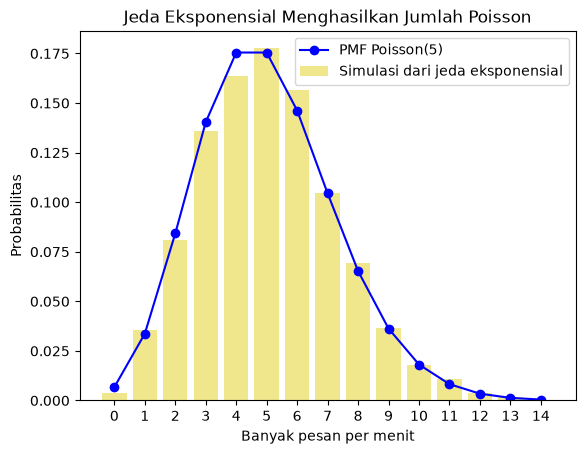

In [12]:
lam = 5                 # pesan per menit
durasi = 2000           # menit
jeda = rng.exponential(1 / lam, size=int(lam * durasi * 1.2))
waktu_datang = np.cumsum(jeda)
waktu_datang = waktu_datang[waktu_datang < durasi]

# Banyak pesan di setiap menit ke-0, 1, ..., 1999
per_menit = np.bincount(waktu_datang.astype(int), minlength=durasi)
print("Total pesan           :", len(waktu_datang))
print(f"Rata-rata jeda        : {jeda.mean():.4f} menit (teori 0,2)")
print(f"Rata-rata per menit   : {per_menit.mean():.4f} (teori 5)")
print(f"Varians per menit     : {per_menit.var():.4f} (teori 5)")

k = np.arange(0, 15)
tabel = pd.DataFrame({"k": k,
                      "Simulasi": [np.mean(per_menit == i) for i in k],
                      "Poisson(5)": stats.poisson.pmf(k, lam)})
print("\n" + tabel.round(4).to_string(index=False))

plt.bar(k, tabel["Simulasi"], color="khaki", label="Simulasi dari jeda eksponensial")
plt.plot(k, tabel["Poisson(5)"], "bo-", label="PMF Poisson(5)")
plt.xticks(k)
plt.xlabel("Banyak pesan per menit")
plt.ylabel("Probabilitas")
plt.title("Jeda Eksponensial Menghasilkan Jumlah Poisson")
plt.legend()
plt.show()

## D12. Variabel Acak Kontinu: Waktu Pemrosesan Request dengan Fungsi Kepadatan

**Soal:** Waktu (detik) yang dibutuhkan server untuk memproses satu request adalah variabel acak kontinu X dengan fungsi kepadatan f(x) = k x (2 - x) untuk 0 <= x <= 2 dan nol di luar selang itu. Tentukan nilai k, P(X > 1,5), P(0,5 < X < 1,5), E(X), dan Var(X), lalu periksa dengan integrasi numerik dan simulasi.

**Perhitungan manual:**

- Syarat fungsi kepadatan: integral f(x) dari 0 sampai 2 = k [x^2 - x^3/3] = k (4 - 8/3) = 4k/3 = 1, sehingga k = 3/4.
- P(X > 1,5) = 3/4 [x^2 - x^3/3] dari 1,5 sampai 2 = 3/4 (4/3 - 1,125) = 0,15625.
- P(0,5 < X < 1,5) = 3/4 [(2,25 - 1,125) - (0,25 - 0,0417)] = 0,6875.
- E(X) = integral x f(x) dx = 3/4 [2x^3/3 - x^4/4] = 1. E(X^2) = 3/4 [x^4/2 - x^5/5] = 1,2, sehingga Var(X) = 1,2 - 1 = 0,2.

k = 3/4 | f(x) = -3*x**2/4 + 3*x/2
P(X > 1,5)       = 5/32 = 0.15625
P(0,5 < X < 1,5) = 11/16 = 0.6875
E(X) = 1 | Var(X) = 1/5

quad: luas total = 1.0 | P(X > 1,5) = 0.15625
Simulasi 266853 data: P(X > 1,5) = 0.1572, rata-rata = 1.0009, varians = 0.2000


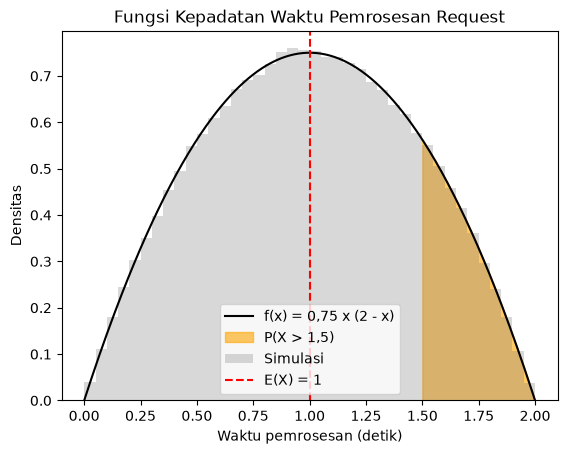

In [13]:
x, k = sp.symbols("x k")
f = k * x * (2 - x)

# Mencari k agar luas di bawah kurva = 1
nilai_k = sp.solve(sp.integrate(f, (x, 0, 2)) - 1, k)[0]
f = f.subs(k, nilai_k)
print("k =", nilai_k, "| f(x) =", sp.expand(f))

p_lebih = sp.integrate(f, (x, sp.Rational(3, 2), 2))
p_antara = sp.integrate(f, (x, sp.Rational(1, 2), sp.Rational(3, 2)))
ex = sp.integrate(x * f, (x, 0, 2))
var = sp.integrate(x**2 * f, (x, 0, 2)) - ex**2
print("P(X > 1,5)       =", p_lebih, "=", float(p_lebih))
print("P(0,5 < X < 1,5) =", p_antara, "=", float(p_antara))
print("E(X) =", ex, "| Var(X) =", var)

# Pemeriksaan dengan integrasi numerik scipy.integrate.quad
f_num = sp.lambdify(x, f)
print("\nquad: luas total =", round(integrate.quad(f_num, 0, 2)[0], 6),
      "| P(X > 1,5) =", round(integrate.quad(f_num, 1.5, 2)[0], 6))

# Simulasi metode penolakan (rejection sampling)
calon = rng.uniform(0, 2, 400_000)
tinggi = rng.uniform(0, 0.75, 400_000)
sampel = calon[tinggi < f_num(calon)]
print(f"Simulasi {len(sampel)} data: P(X > 1,5) = {np.mean(sampel > 1.5):.4f}, "
      f"rata-rata = {sampel.mean():.4f}, varians = {sampel.var():.4f}")

xs = np.linspace(0, 2, 300)
plt.plot(xs, f_num(xs), color="black", label="f(x) = 0,75 x (2 - x)")
xa = np.linspace(1.5, 2, 100)
plt.fill_between(xa, f_num(xa), color="orange", alpha=0.6, label="P(X > 1,5)")
plt.hist(sampel, bins=40, density=True, alpha=0.3, color="gray", label="Simulasi")
plt.axvline(float(ex), color="red", linestyle="--", label="E(X) = 1")
plt.xlabel("Waktu pemrosesan (detik)")
plt.ylabel("Densitas")
plt.title("Fungsi Kepadatan Waktu Pemrosesan Request")
plt.legend()
plt.show()

## D13. Distribusi Seragam Diskrit: Digit Kode OTP

**Soal:** Setiap digit kode OTP dibangkitkan acak dari 0 sampai 9 dengan peluang sama dan saling bebas. Misalkan X adalah nilai satu digit. Tentukan P(X = 7), P(X >= 5), E(X), dan Var(X). Tentukan juga peluang OTP 6 digit seluruhnya berisi digit genap, lalu bandingkan dengan simulasi 100.000 OTP.

**Perhitungan manual:**

- X ~ Seragam diskrit pada {0, 1, ..., 9} dengan n = 10, sehingga P(X = x) = 1/10.
- P(X = 7) = 0,1 dan P(X >= 5) = 5/10 = 0,5.
- E(X) = (0 + 9)/2 = 4,5 dan Var(X) = (n^2 - 1)/12 = 99/12 = 8,25.
- P(digit genap) = 5/10 = 0,5, sehingga P(6 digit genap semua) = 0,5^6 = 0,015625.

P(X = 7)  = 0.1000 | manual 1/10
P(X >= 5) = 0.5000 | manual 5/10
E(X)   = 4.5 | manual (0 + 9)/2 = 4.5
Var(X) = 8.25 | manual (10^2 - 1)/12 = 8.25
P(OTP 6 digit genap semua) = 0.015625

Simulasi: rata-rata digit = 4.5031, varians = 8.2308
Simulasi P(6 digit genap semua) = 0.01511


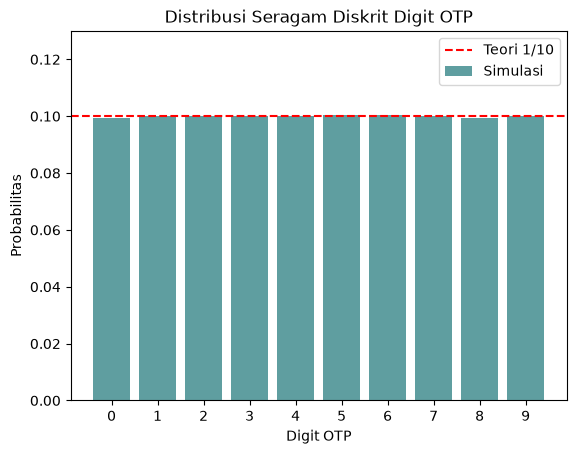

In [14]:
X = stats.randint(0, 10)   # nilai bulat 0 sampai 9
print(f"P(X = 7)  = {X.pmf(7):.4f} | manual 1/10")
print(f"P(X >= 5) = {X.sf(4):.4f} | manual 5/10")
print(f"E(X)   = {X.mean()} | manual (0 + 9)/2 = {(0 + 9) / 2}")
print(f"Var(X) = {X.var()} | manual (10^2 - 1)/12 = {(10**2 - 1) / 12}")
print(f"P(OTP 6 digit genap semua) = {0.5 ** 6}")

# Simulasi 100.000 kode OTP 6 digit
otp = rng.integers(0, 10, size=(100_000, 6))
print(f"\nSimulasi: rata-rata digit = {otp.mean():.4f}, varians = {otp.var():.4f}")
print(f"Simulasi P(6 digit genap semua) = {np.mean((otp % 2 == 0).all(axis=1)):.5f}")

frek = pd.Series(otp.ravel()).value_counts(normalize=True).sort_index()
plt.bar(frek.index, frek.values, color="cadetblue", label="Simulasi")
plt.axhline(0.1, color="red", linestyle="--", label="Teori 1/10")
plt.xticks(range(10))
plt.ylim(0, 0.13)
plt.xlabel("Digit OTP")
plt.ylabel("Probabilitas")
plt.title("Distribusi Seragam Diskrit Digit OTP")
plt.legend()
plt.show()

## D14. Distribusi Binomial Negatif: Unduhan Berhasil ke-3 pada Web Crawler

**Soal:** Sebuah web crawler mencoba mengunduh halaman satu per satu. Setiap percobaan berhasil dengan peluang 0,6 secara saling bebas. Misalkan X adalah banyak percobaan sampai unduhan berhasil ketiga terjadi. Tentukan P(X = 5), P(X <= 6), E(X), dan Var(X), lalu bandingkan dengan simulasi.

**Perhitungan manual:**

- P(X = x) = C(x - 1, r - 1) p^r (1 - p)^(x - r) dengan r = 3 dan p = 0,6.
- P(X = 5) = C(4,2) (0,6)^3 (0,4)^2 = 6 x 0,216 x 0,16 = 0,2074.
- P(X <= 6) = P(3) + P(4) + P(5) + P(6) = 0,2160 + 0,2592 + 0,2074 + 0,1382 = 0,8208.
- E(X) = r/p = 3/0,6 = 5 dan Var(X) = r(1 - p)/p^2 = 1,2/0,36 = 3,3333.

P(X = 5)  manual = 0.2074 | scipy = 0.2074
P(X <= 6) manual = 0.8208 | scipy = 0.8208
E(X)   = 5.0000 (r/p = 5.0000)
Var(X) = 3.3333 (r(1-p)/p^2 = 3.3333)

Simulasi: rata-rata = 4.9989, varians = 3.3467, P(X = 5) = 0.2072


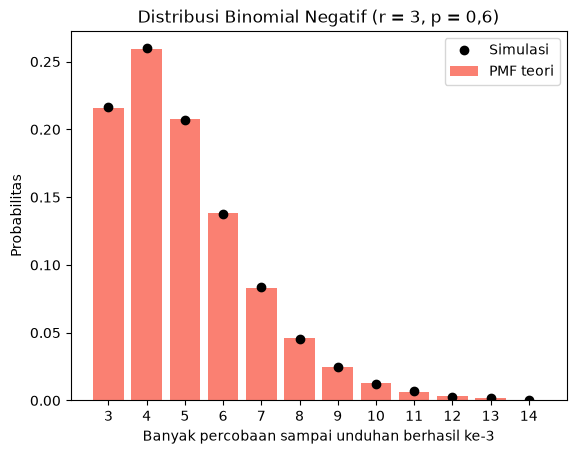

In [15]:
r, p = 3, 0.6
# scipy.stats.nbinom menghitung banyak GAGAL sebelum sukses ke-r, sehingga X = gagal + r
Y = stats.nbinom(r, p)

def pmf_manual(x):
    return math.comb(x - 1, r - 1) * p**r * (1 - p)**(x - r)

print(f"P(X = 5)  manual = {pmf_manual(5):.4f} | scipy = {Y.pmf(5 - r):.4f}")
print(f"P(X <= 6) manual = {sum(pmf_manual(x) for x in range(3, 7)):.4f} | scipy = {Y.cdf(6 - r):.4f}")
print(f"E(X)   = {Y.mean() + r:.4f} (r/p = {r / p:.4f})")
print(f"Var(X) = {Y.var():.4f} (r(1-p)/p^2 = {r * (1 - p) / p**2:.4f})")

# Simulasi: X = jumlah dari r variabel geometrik
sim = rng.geometric(p, size=(50_000, r)).sum(axis=1)
print(f"\nSimulasi: rata-rata = {sim.mean():.4f}, varians = {sim.var():.4f}, "
      f"P(X = 5) = {np.mean(sim == 5):.4f}")

xs = np.arange(3, 15)
plt.bar(xs, Y.pmf(xs - r), color="salmon", label="PMF teori")
plt.plot(xs, [np.mean(sim == i) for i in xs], "ko", label="Simulasi")
plt.xticks(xs)
plt.xlabel("Banyak percobaan sampai unduhan berhasil ke-3")
plt.ylabel("Probabilitas")
plt.title("Distribusi Binomial Negatif (r = 3, p = 0,6)")
plt.legend()
plt.show()

## D15. Ringkasan Nilai Harapan dan Varians Seluruh Distribusi

**Soal:** Buat tabel ringkasan nilai harapan dan varians dari seluruh distribusi yang telah dieksplorasi, lalu bandingkan hasil fungsi scipy.stats dengan rumus manual.

**Perhitungan manual:**

- Bernoulli: E = p, Var = p(1 - p). Binomial: E = np, Var = np(1 - p). Seragam diskrit: E = (a + b)/2, Var = (n^2 - 1)/12.
- Poisson: E = Var = lambda. Geometrik: E = 1/p, Var = (1 - p)/p^2. Binomial negatif (banyak gagal): E = r(1 - p)/p, Var = r(1 - p)/p^2.
- Hipergeometrik: E = nK/N, Var = n(K/N)(1 - K/N)(N - n)/(N - 1).
- Uniform: E = (a + b)/2, Var = (b - a)^2/12. Normal: E = mu, Var = sigma^2. Eksponensial: E = 1/lambda, Var = 1/lambda^2.

In [16]:
distribusi = {
    "Bernoulli(0,78)":        (stats.bernoulli(0.78),      0.78,      0.78 * 0.22),
    "Binomial(12; 0,1)":      (stats.binom(12, 0.1),       1.2,       12 * 0.1 * 0.9),
    "Seragam diskrit(0..9)":  (stats.randint(0, 10),       4.5,       (10**2 - 1) / 12),
    "Poisson(6)":             (stats.poisson(6),           6.0,       6.0),
    "Geometrik(0,15)":        (stats.geom(0.15),           1 / 0.15,  0.85 / 0.15**2),
    "Binom. negatif(3; 0,6)": (stats.nbinom(3, 0.6),       3 * 0.4 / 0.6, 3 * 0.4 / 0.6**2),
    "Hipergeometrik(30,4,6)": (stats.hypergeom(30, 4, 6),  6 * 4 / 30, 6 * (4/30) * (26/30) * 24 / 29),
    "Uniform(20, 80)":        (stats.uniform(20, 60),      50.0,      60**2 / 12),
    "Normal(72; 6)":          (stats.norm(72, 6),          72.0,      6.0**2),
    "Eksponensial(rata 8)":   (stats.expon(scale=8),       8.0,       8.0**2),
}

baris = []
for nama, (dist, e_manual, var_manual) in distribusi.items():
    baris.append([nama, dist.mean(), e_manual, dist.var(), var_manual])
ringkasan = pd.DataFrame(baris, columns=["Distribusi", "E scipy", "E manual", "Var scipy", "Var manual"])
ringkasan["Sama?"] = np.isclose(ringkasan["E scipy"], ringkasan["E manual"]) & \
                     np.isclose(ringkasan["Var scipy"], ringkasan["Var manual"])
pd.set_option("display.width", 120)
print(ringkasan.round(4).to_string(index=False))

            Distribusi  E scipy  E manual  Var scipy  Var manual  Sama?
       Bernoulli(0,78)   0.7800    0.7800     0.1716      0.1716   True
     Binomial(12; 0,1)   1.2000    1.2000     1.0800      1.0800   True
 Seragam diskrit(0..9)   4.5000    4.5000     8.2500      8.2500   True
            Poisson(6)   6.0000    6.0000     6.0000      6.0000   True
       Geometrik(0,15)   6.6667    6.6667    37.7778     37.7778   True
Binom. negatif(3; 0,6)   2.0000    2.0000     3.3333      3.3333   True
Hipergeometrik(30,4,6)   0.8000    0.8000     0.5738      0.5738   True
       Uniform(20, 80)  50.0000   50.0000   300.0000    300.0000   True
         Normal(72; 6)  72.0000   72.0000    36.0000     36.0000   True
  Eksponensial(rata 8)   8.0000    8.0000    64.0000     64.0000   True
